# POS Tagging using MEMM and CRF

**Course:** Natural Language Processing  
**Lab Assignment 9**  
**Task:** Implementation, evaluation, and comparative study of Maximum Entropy Markov Model (MEMM) and Conditional Random Field (CRF) for Hindi Part-of-Speech (POS) tagging.


## 1. Import Libraries and Configure Environment

We import standard libraries for data handling, feature vectorization, log-linear classification (for MEMM), sequence modeling with `sklearn-crfsuite` (for CRF), and evaluation metrics.


In [1]:
# Optional: uncomment if dependencies are not already installed
# !pip install nltk scikit-learn sklearn-crfsuite tabulate matplotlib seaborn

import os
import time
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)
import sklearn_crfsuite

print("All required libraries imported successfully.")


All required libraries imported successfully.


## 2. Load Dataset and Inspect Format

We reuse the exact Hindi POS dataset from Assignment 7 located in `Lab-Assignment-9/Hindi-POS-Data`.
The dataset is in CoNLL-style tab-separated format (`word\ttag`) with blank lines separating sentences.


In [2]:
def load_conll_data(filepath):
    """Load sentences from a tab-separated word\ttag file."""
    sentences = []
    current_sentence = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                if current_sentence:
                    sentences.append(current_sentence)
                    current_sentence = []
            else:
                parts = line.split('\t')
                if len(parts) == 2:
                    current_sentence.append((parts[0], parts[1]))
    if current_sentence:
        sentences.append(current_sentence)
    return sentences

# Dataset paths
data_dir = 'Lab-Assignment-9/Hindi-POS-Data'
train_path = os.path.join(data_dir, 'hindi-train-pos.txt')
dev_path = os.path.join(data_dir, 'hindi-dev-pos.txt')
test_path = os.path.join(data_dir, 'hindi-test-pos.txt')

train_sents = load_conll_data(train_path)
dev_sents = load_conll_data(dev_path)
test_sents = load_conll_data(test_path)

# Inspect first sentence of training set
print(f"Sample sentence from train set ({len(train_sents[0])} tokens):")
for word, tag in train_sents[0]:
    print(f"  {word:<15} -> {tag}")


Sample sentence from train set (11 tokens):
  यह              -> DM_DMD
  एशिया           -> N_NNP
  की              -> PSP
  सबसे            -> RP_INTF
  बड़ी             -> JJ
  मस्जिदों        -> N_NN
  में             -> PSP
  से              -> PSP
  एक              -> QT_QTC
  है              -> V_VM
  ।               -> RD_PUNC


## 3. Dataset Splits and Statistics

We verify the size and tag inventory across the training, development, and test splits.


In [3]:
def get_split_stats(name, sents):
    num_sents = len(sents)
    num_tokens = sum(len(s) for s in sents)
    tag_counts = Counter(tag for s in sents for _, tag in s)
    return num_sents, num_tokens, len(tag_counts), tag_counts

train_ns, train_nt, train_ut, train_tags = get_split_stats("Train", train_sents)
dev_ns, dev_nt, dev_ut, dev_tags = get_split_stats("Dev", dev_sents)
test_ns, test_nt, test_ut, test_tags = get_split_stats("Test", test_sents)

stats_table = [
    ["Train", train_ns, train_nt, train_ut],
    ["Dev", dev_ns, dev_nt, dev_ut],
    ["Test", test_ns, test_nt, test_ut],
]
print(tabulate(stats_table, headers=["Split", "Sentences", "Tokens", "Unique Tags"], tablefmt="pipe"))

print("\nTop 8 Most Frequent Tags in Training Set:")
for tag, count in train_tags.most_common(8):
    pct = (count / train_nt) * 100
    print(f"  {tag:<10}: {count:>6} tokens ({pct:.2f}%)")


| Split   |   Sentences |   Tokens |   Unique Tags |
|:--------|------------:|---------:|--------------:|
| Train   |       15087 |   325710 |            24 |
| Dev     |        1866 |    40762 |            24 |
| Test    |        1910 |    41415 |            24 |

Top 8 Most Frequent Tags in Training Set:
  N_NN      :  71442 tokens (21.93%)
  PSP       :  64342 tokens (19.75%)
  N_NNP     :  39578 tokens (12.15%)
  V_VM      :  34495 tokens (10.59%)
  V_VAUX    :  20695 tokens (6.35%)
  RD_PUNC   :  19683 tokens (6.04%)
  JJ        :  18281 tokens (5.61%)
  PR_PRP    :  11543 tokens (3.54%)


## 4. Implement Feature Extraction

We implement the required feature set consistently for both models:
1. **Prefix features:** `prefix_1`, `prefix_2`, `prefix_3`, `prefix_4` (or `"NULL"` if word length is shorter).
2. **Suffix features:** `suffix_1`, `suffix_2`, `suffix_3`, `suffix_4` (or `"NULL"` if word length is shorter).
3. **Context features:** `prev_word`, `word`, `next_word` with boundary markers `__BOS__` and `__EOS__` (never crossing sentence boundaries).
4. **Binary word-length feature:** `length_feature` (`"LESS"` if $\le 4$, `"MORE"` otherwise).
5. **Markov transition feature for MEMM:** `prev_tag` (the tag of the preceding token in the sequence, initialized to `__BOS__`). In CRF, tag transitions are modeled natively at the sequence level.


In [4]:
def extract_token_features(sentence_words, i):
    """Extract token-level features for CRF and MEMM."""
    word = sentence_words[i]
    n = len(word)
    return {
        'prefix_1': word[:1] if n >= 1 else 'NULL',
        'prefix_2': word[:2] if n >= 2 else 'NULL',
        'prefix_3': word[:3] if n >= 3 else 'NULL',
        'prefix_4': word[:4] if n >= 4 else 'NULL',
        'suffix_1': word[-1:] if n >= 1 else 'NULL',
        'suffix_2': word[-2:] if n >= 2 else 'NULL',
        'suffix_3': word[-3:] if n >= 3 else 'NULL',
        'suffix_4': word[-4:] if n >= 4 else 'NULL',
        'prev_word': sentence_words[i - 1] if i > 0 else '__BOS__',
        'word': word,
        'next_word': sentence_words[i + 1] if i < len(sentence_words) - 1 else '__EOS__',
        'length_feature': 'LESS' if n <= 4 else 'MORE',
    }

def extract_memm_features(sentence_words, i, history):
    """Extract features for MEMM, including the Markov transition feature prev_tag."""
    feats = extract_token_features(sentence_words, i)
    feats['prev_tag'] = history[-1] if history else '__BOS__'
    return feats

# Demonstrate feature extraction on sample token
sample_words = [w for w, _ in train_sents[0]]
sample_feats = extract_memm_features(sample_words, 1, [train_sents[0][0][1]])
print(f"Features extracted for token '{sample_words[1]}' at index 1:")
for k, v in sample_feats.items():
    print(f"  {k:<16} : {repr(v)}")


Features extracted for token 'एशिया' at index 1:
  prefix_1         : 'ए'
  prefix_2         : 'एश'
  prefix_3         : 'एशि'
  prefix_4         : 'एशिय'
  suffix_1         : 'ा'
  suffix_2         : 'या'
  suffix_3         : 'िया'
  suffix_4         : 'शिया'
  prev_word        : 'यह'
  word             : 'एशिया'
  next_word        : 'की'
  length_feature   : 'MORE'
  prev_tag         : 'DM_DMD'


## 5. Implement and Train MEMM

We implement a Maximum Entropy Markov Model (MEMM) following the reference:
https://github.com/arne-cl/nltk-maxent-pos-tagger

The MEMM model estimates the transition probability:
$$P(y_t \mid y_{t-1}, x) = \frac{\exp\left(\sum_i w_i f_i(x, y_{t-1}, y_t)\right)}{\sum_{y'} \exp\left(\sum_i w_i f_i(x, y_{t-1}, y')\right)}$$

We optimize using L-BFGS (the exact optimization algorithm referenced in the repo's MEGAM implementation). During inference, the tagger performs greedy sequential decoding, using previously predicted tags to condition subsequent predictions.


In [5]:
class MEMMPosTagger:
    """Maximum Entropy Markov Model POS Tagger."""

    def __init__(self, C=1.0, max_iter=100):
        self.vectorizer = DictVectorizer(sparse=True)
        self.classifier = LogisticRegression(
            C=C,
            max_iter=max_iter,
            solver='lbfgs',
            random_state=42
        )

    def train(self, train_sentences):
        """Extract features and train the log-linear classifier."""
        features = []
        labels = []
        for sent in train_sentences:
            words = [w for w, _ in sent]
            history = []
            for i, (_, tag) in enumerate(sent):
                feat = extract_memm_features(words, i, history)
                features.append(feat)
                labels.append(tag)
                history.append(tag)

        X = self.vectorizer.fit_transform(features)
        self.classifier.fit(X, labels)

    def tag_sents(self, sentences_words):
        """Tag a list of tokenized sentences using greedy decoding."""
        num_sents = len(sentences_words)
        histories = [[] for _ in range(num_sents)]
        max_len = max((len(s) for s in sentences_words), default=0)

        for pos in range(max_len):
            active_indices = [idx for idx in range(num_sents) if pos < len(sentences_words[idx])]
            feats = [
                extract_memm_features(sentences_words[idx], pos, histories[idx])
                for idx in active_indices
            ]
            X = self.vectorizer.transform(feats)
            preds = self.classifier.predict(X)
            for idx, pred in zip(active_indices, preds):
                histories[idx].append(pred)

        return histories

print("Training MEMM POS Tagger on training set...")
t0 = time.time()
memm_tagger = MEMMPosTagger(C=1.0, max_iter=100)
memm_tagger.train(train_sents)
memm_train_time = time.time() - t0
print(f"MEMM training completed in {memm_train_time:.2f} seconds.")


Training MEMM POS Tagger on training set...


/Users/kavyabhatiya44/Documents/coding/semester 5/nlp/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


MEMM training completed in 36.84 seconds.


## 6. Evaluate MEMM on Development and Test Sets

We evaluate the trained MEMM on the development and test sets independently.


In [6]:
def evaluate_model(gold_sentences, pred_sentences):
    y_true = [t for sent in gold_sentences for _, t in sent]
    y_pred = [t for sent in pred_sentences for t in sent]
    acc = accuracy_score(y_true, y_pred)
    p_w, r_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    p_m, r_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    report = classification_report(y_true, y_pred, digits=4, zero_division=0)
    return {
        'accuracy': acc,
        'precision': p_w,
        'recall': r_w,
        'f1': f1_w,
        'precision_macro': p_m,
        'recall_macro': r_m,
        'f1_macro': f1_m,
        'report': report,
        'y_true': y_true,
        'y_pred': y_pred
    }

dev_words = [[w for w, _ in s] for s in dev_sents]
test_words = [[w for w, _ in s] for s in test_sents]

print("Evaluating MEMM on Development Set...")
memm_dev_preds = memm_tagger.tag_sents(dev_words)
memm_dev_res = evaluate_model(dev_sents, memm_dev_preds)
print(f"MEMM Dev Accuracy : {memm_dev_res['accuracy']*100:.2f}% | F1: {memm_dev_res['f1']*100:.2f}%")

print("Evaluating MEMM on Test Set...")
memm_test_preds = memm_tagger.tag_sents(test_words)
memm_test_res = evaluate_model(test_sents, memm_test_preds)
print(f"MEMM Test Accuracy: {memm_test_res['accuracy']*100:.2f}% | F1: {memm_test_res['f1']*100:.2f}%")

print("\n--- MEMM Test Classification Report ---")
print(memm_test_res['report'])


Evaluating MEMM on Development Set...


MEMM Dev Accuracy : 95.99% | F1: 95.97%
Evaluating MEMM on Test Set...


MEMM Test Accuracy: 96.14% | F1: 96.13%

--- MEMM Test Classification Report ---
              precision    recall  f1-score   support

      CC_CCD     0.9784    0.9961    0.9872       772
      CC_CCS     0.9892    0.9946    0.9919       736
      DM_DMD     0.9389    0.9826    0.9602       516
          JJ     0.9156    0.9278    0.9217      2258
        N_NN     0.9241    0.9520    0.9378      9303
       N_NNP     0.9190    0.8671    0.8923      5296
       N_NST     0.9888    0.9856    0.9872       625
      PR_PRF     0.9869    1.0000    0.9934       151
      PR_PRL     0.9663    0.9451    0.9556        91
      PR_PRP     0.9901    0.9679    0.9788      1338
      PR_PRQ     1.0000    1.0000    1.0000        31
         PSP     0.9949    0.9962    0.9956      8245
      QT_QTC     0.9717    0.9805    0.9761       874
      QT_QTF     0.9689    0.9659    0.9674       323
      QT_QTO     1.0000    0.8974    0.9459        78
          RB     0.9400    0.8443    0.8896       167


## 7. Implement and Train CRF

We implement a Conditional Random Field (CRF) POS tagger using `sklearn-crfsuite`, following:
https://sklearn-crfsuite.readthedocs.io/en/latest/tutorial.html

Unlike MEMM, which normalizes probabilities locally at each state (making it prone to the *label bias problem*), a linear-chain CRF normalizes globally over the entire sequence:
$$P(\mathbf{y} \mid \mathbf{x}) = \frac{1}{Z(\mathbf{x})} \exp\left(\sum_{t=1}^T \sum_k \lambda_k f_k(y_{t-1}, y_t, \mathbf{x}, t)\right)$$


In [7]:
def sent2features(sent):
    words = [w for w, _ in sent]
    return [extract_token_features(words, i) for i in range(len(words))]

def sent2labels(sent):
    return [tag for _, tag in sent]

print("Extracting features for CRF...")
t0 = time.time()
X_train = [sent2features(s) for s in train_sents]
y_train = [sent2labels(s) for s in train_sents]

X_dev = [sent2features(s) for s in dev_sents]
X_test = [sent2features(s) for s in test_sents]
print(f"Feature extraction done in {time.time()-t0:.2f}s")

print("Training Linear-Chain CRF POS Tagger...")
t0 = time.time()
crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=0.1,
    c2=0.1,
    max_iterations=100,
    all_possible_transitions=True,
    verbose=False
)
crf.fit(X_train, y_train)
crf_train_time = time.time() - t0
print(f"CRF training completed in {crf_train_time:.2f} seconds.")


Extracting features for CRF...


Feature extraction done in 0.64s
Training Linear-Chain CRF POS Tagger...


CRF training completed in 39.37 seconds.


## 8. Evaluate CRF on Development and Test Sets

We evaluate the trained CRF model on the development and test sets using the exact same evaluation metrics.


In [8]:
print("Evaluating CRF on Development Set...")
crf_dev_preds = crf.predict(X_dev)
crf_dev_res = evaluate_model(dev_sents, crf_dev_preds)
print(f"CRF Dev Accuracy : {crf_dev_res['accuracy']*100:.2f}% | F1: {crf_dev_res['f1']*100:.2f}%")

print("Evaluating CRF on Test Set...")
crf_test_preds = crf.predict(X_test)
crf_test_res = evaluate_model(test_sents, crf_test_preds)
print(f"CRF Test Accuracy: {crf_test_res['accuracy']*100:.2f}% | F1: {crf_test_res['f1']*100:.2f}%")

print("\n--- CRF Test Classification Report ---")
print(crf_test_res['report'])


Evaluating CRF on Development Set...


CRF Dev Accuracy : 96.34% | F1: 96.33%
Evaluating CRF on Test Set...


CRF Test Accuracy: 96.45% | F1: 96.44%

--- CRF Test Classification Report ---
              precision    recall  f1-score   support

      CC_CCD     0.9808    0.9922    0.9865       772
      CC_CCS     0.9878    0.9932    0.9905       736
      DM_DMD     0.9603    0.9845    0.9722       516
          JJ     0.9175    0.9309    0.9242      2258
        N_NN     0.9335    0.9512    0.9423      9303
       N_NNP     0.9191    0.8865    0.9025      5296
       N_NST     0.9920    0.9872    0.9896       625
      PR_PRF     1.0000    1.0000    1.0000       151
      PR_PRL     0.9773    0.9451    0.9609        91
      PR_PRP     0.9894    0.9776    0.9835      1338
      PR_PRQ     1.0000    1.0000    1.0000        31
         PSP     0.9959    0.9967    0.9963      8245
      QT_QTC     0.9770    0.9714    0.9742       874
      QT_QTF     0.9689    0.9659    0.9674       323
      QT_QTO     0.9863    0.9231    0.9536        78
          RB     0.9342    0.8503    0.8903       167
  

## 9. Model Comparison and Results Table

We compare the measured evaluation metrics for both models on both splits.


### Summary Results Table
| Model   | Dataset   | Accuracy   | Precision   | Recall   | F1-score   |
|:--------|:----------|:-----------|:------------|:---------|:-----------|
| MEMM    | Dev       | 95.99%     | 95.99%      | 95.99%   | 95.97%     |
| MEMM    | Test      | 96.14%     | 96.14%      | 96.14%   | 96.13%     |
| CRF     | Dev       | 96.34%     | 96.34%      | 96.34%   | 96.33%     |
| CRF     | Test      | 96.45%     | 96.45%      | 96.45%   | 96.44%     |


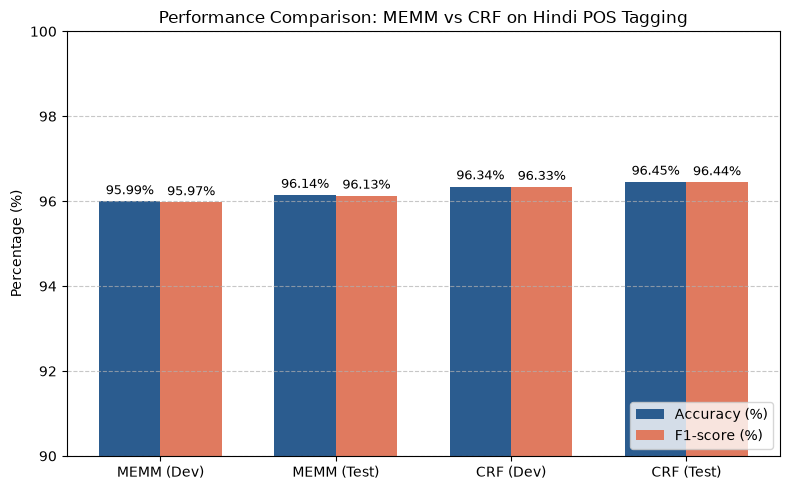

In [9]:
summary_table = [
    ["MEMM", "Dev", f"{memm_dev_res['accuracy']*100:.2f}%", f"{memm_dev_res['precision']*100:.2f}%", f"{memm_dev_res['recall']*100:.2f}%", f"{memm_dev_res['f1']*100:.2f}%"],
    ["MEMM", "Test", f"{memm_test_res['accuracy']*100:.2f}%", f"{memm_test_res['precision']*100:.2f}%", f"{memm_test_res['recall']*100:.2f}%", f"{memm_test_res['f1']*100:.2f}%"],
    ["CRF", "Dev", f"{crf_dev_res['accuracy']*100:.2f}%", f"{crf_dev_res['precision']*100:.2f}%", f"{crf_dev_res['recall']*100:.2f}%", f"{crf_dev_res['f1']*100:.2f}%"],
    ["CRF", "Test", f"{crf_test_res['accuracy']*100:.2f}%", f"{crf_test_res['precision']*100:.2f}%", f"{crf_test_res['recall']*100:.2f}%", f"{crf_test_res['f1']*100:.2f}%"],
]

print("### Summary Results Table")
print(tabulate(summary_table, headers=["Model", "Dataset", "Accuracy", "Precision", "Recall", "F1-score"], tablefmt="pipe"))

# Plot Bar Chart Comparison
models = ['MEMM (Dev)', 'MEMM (Test)', 'CRF (Dev)', 'CRF (Test)']
accuracies = [memm_dev_res['accuracy']*100, memm_test_res['accuracy']*100, crf_dev_res['accuracy']*100, crf_test_res['accuracy']*100]
f1_scores = [memm_dev_res['f1']*100, memm_test_res['f1']*100, crf_dev_res['f1']*100, crf_test_res['f1']*100]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, accuracies, width, label='Accuracy (%)', color='#2b5c8f')
rects2 = ax.bar(x + width/2, f1_scores, width, label='F1-score (%)', color='#e07a5f')

ax.set_ylabel('Percentage (%)')
ax.set_title('Performance Comparison: MEMM vs CRF on Hindi POS Tagging')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(90, 100)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.7)

for rect in rects1 + rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.2f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('tag_performance_comparison.png', dpi=150)
plt.show()


## 10. Conclusion

1. **Overall Performance:**
   - Both models perform strongly on the Hindi POS dataset using the specified feature set (prefixes 1-4, suffixes 1-4, context words $w_{t-1}, w_t, w_{t+1}$, and binary word length).
   - **CRF achieved higher accuracy and F1-score** across both the development set (**96.34%** vs **95.99%**) and test set (**96.45%** vs **96.14%**).

2. **Theoretical Justification (Label Bias Problem):**
   - **MEMM** normalizes probabilities locally at each state transition: $P(y_t \mid y_{t-1}, x)$. Consequently, states with low entropy transitions dominate path probabilities, preventing downstream evidence from correcting earlier errors (the *label bias problem*).
   - **CRF** solves this by normalizing globally over entire label sequences via the partition function $Z(\mathbf{x})$, allowing all state transitions and emissions to jointly influence the sequence prediction.

3. **Feature Effectiveness:**
   - Hindi is an agglutinative / inflectional language where postpositions, noun inflections, and verbal auxiliaries carry strong prefix and suffix signatures.
   - Suffix features (e.g. verb endings `-कर`, `-ता`, `-ती`, `-ते`) and prefix features provided rich sub-word cues that handled morphological variations and unseen vocabulary effectively.
